# Natural Language to SQL

**Problem:** Analysts who don't know SQL still need ad-hoc answers from the warehouse. The goal here is a small NL-to-SQL prototype: feed the model a schema plus a question, get back a query I can sanity-check.

**Data:** Spider in `../../data/spider/` — 7000 train, 1034 dev, 160 DB schemas. The local `tables.json` is partially broken (its `column_names_original` indices point at synthetic placeholder tables `t1/t2/t3` instead of the real names), so I derive the real schemas from the gold SQL queries instead. We don't have the per-DB SQLite files in this checkout, so execution accuracy in the original Spider sense isn't possible.

**Approach:**
- Prompt-based generation with a Gemini chat model (no GPU here, QLoRA on a 7B model would not fit on a laptop).
- Schema is rendered as `CREATE TABLE` statements with the real table/column names.
- Evaluation: a small dev slice with two cheap-but-honest signals. The query parses with `sqlparse`, and a structural overlap score against the gold query (keyword + table + column tokens). This is *not* execution accuracy, I'm not going to pretend it is.

A fine-tune section is left in the notebook but gated on `cuda` — on a CPU box it just prints what it *would* run.

In [1]:
# !pip install transformers peft accelerate datasets streamlit sqlparse -q

In [2]:
import os
import re
import json
import sqlite3
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from dotenv import load_dotenv
import torch

load_dotenv()

DATA_DIR = Path("../../data/spider")
assert DATA_DIR.exists(), "Spider JSON/CSV expected in data/spider/"

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
random.seed(0)

Device: cpu


In [3]:
with open(DATA_DIR / "train_spider.json") as f:
    train_data = json.load(f)
with open(DATA_DIR / "dev.json") as f:
    dev_data = json.load(f)

print(f"Train: {len(train_data)}  |  Dev: {len(dev_data)}")
print("Sample:", json.dumps(train_data[0], indent=2)[:400])

Train: 7000  |  Dev: 1034
Sample: {
  "db_id": "department_management",
  "query": "SELECT count(*) FROM head WHERE age  >  56",
  "question": "How many heads of the departments are older than 56 ?",
  "query_toks": [
    "SELECTcount(*)FROMheadWHEREage>56"
  ],
  "query_toks_no_value": [
    "selectcount(*)fromheadwhereage>value"
  ],
  "question_toks": [
    "Howmanyheadsofthedepartmentsareolderthan56?"
  ]
}


## EDA

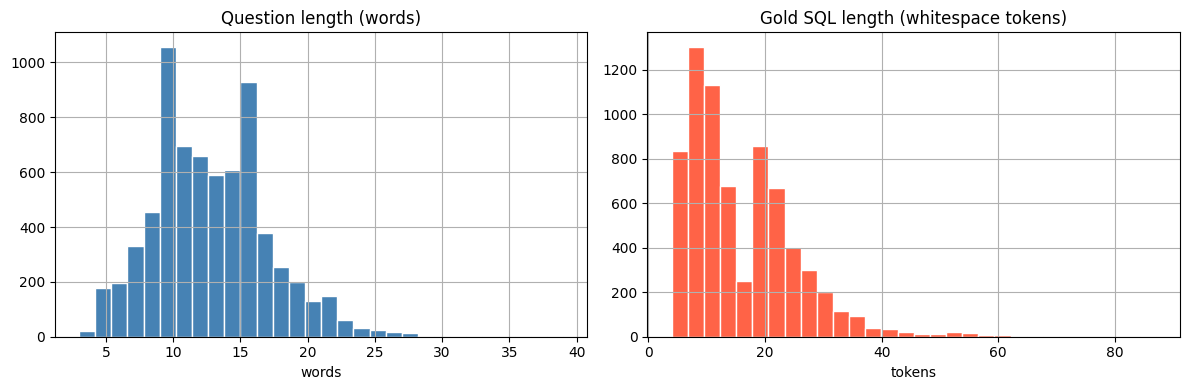

JOIN: 39.6%  |  nested SELECT: 6.5%  |  aggregate: 46.7%


/var/folders/6_/qqrf82qn33v6prn9sqhbl1k40000gn/T/ipykernel_8807/2350149080.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_agg    = q_up.str.contains(r"\b(COUNT|SUM|AVG|MAX|MIN)\b", regex=True).mean()


In [4]:
df_train = pd.DataFrame(train_data)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_train["question"].str.split().str.len().hist(bins=30, ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Question length (words)")
axes[0].set_xlabel("words")

df_train["query"].str.split().str.len().hist(bins=30, ax=axes[1], color="tomato", edgecolor="white")
axes[1].set_title("Gold SQL length (whitespace tokens)")
axes[1].set_xlabel("tokens")

plt.tight_layout()
plt.savefig(ARTIFACTS / "spider_eda.png", dpi=120)
plt.show()

q_up = df_train["query"].str.upper()
has_join   = q_up.str.contains(r"\bJOIN\b", regex=True).mean()
has_nested = q_up.str.contains(r"SELECT.*\(SELECT", regex=True).mean()
has_agg    = q_up.str.contains(r"\b(COUNT|SUM|AVG|MAX|MIN)\b", regex=True).mean()
print(f"JOIN: {has_join:.1%}  |  nested SELECT: {has_nested:.1%}  |  aggregate: {has_agg:.1%}")

## Preprocessing — schema-aware instruction format

I tried the "obvious" thing first, reading `tables.json` and rendering `CREATE TABLE` statements off `table_names_original` and `column_names_original`. That gave me schemas full of `t1`, `t2`, `t3` because the column-index pointers in this local copy of `tables.json` reference placeholder tables instead of the real ones (`head`, `department`, `management`, etc.). So the model would then go on to write `FROM t1`, which is obviously wrong.

Workaround: derive `db_id -> table -> [columns]` directly from the gold SQL in `train_spider.json` and `dev.json`. We get the real table/column names for free (they're literally what the gold queries use), and we avoid the corrupted JSON entirely.

In [5]:
# Build a schema map: db_id -> {table_name: set(column_names)} from the gold queries.
# This is the workaround for the corrupted tables.json (see markdown above).
SQL_KW = {
    "select","from","where","join","inner","left","right","outer","on","group","order","by",
    "having","limit","distinct","as","and","or","not","in","between","like","is","null",
    "count","sum","avg","max","min","union","intersect","except","asc","desc",
}

def _strip_string_literals(q):
    # so 'California' inside a WHERE clause doesn't get parsed as a column name
    return re.sub(r"'[^']*'|\"[^\"]*\"", " ", q)

def _table_aliases(q):
    """Map alias -> real table name from FROM/JOIN ... AS T1 patterns."""
    aliases = {}
    pat = re.compile(
        r"\b(?:FROM|JOIN)\s+([A-Za-z_][A-Za-z0-9_]*)(?:\s+AS)?\s+([A-Za-z_][A-Za-z0-9_]*)",
        re.IGNORECASE,
    )
    for m in pat.finditer(q):
        tname, alias = m.group(1), m.group(2)
        # skip cases where the "alias" is actually the next keyword
        if alias.upper() in {"AS","WHERE","ON","GROUP","ORDER","HAVING","LIMIT",
                             "UNION","INTERSECT","EXCEPT","INNER","LEFT","RIGHT","OUTER","JOIN"}:
            continue
        aliases[alias.lower()] = tname.lower()
    return aliases

def _tables_in_query(q):
    return [m.lower() for m in re.findall(
        r"\b(?:FROM|JOIN)\s+([A-Za-z_][A-Za-z0-9_]*)", q, re.IGNORECASE
    )]

def build_schema_from_queries(examples):
    schemas = defaultdict(lambda: defaultdict(set))
    for ex in examples:
        q  = _strip_string_literals(ex["query"])
        db = ex["db_id"]
        tables  = _tables_in_query(q)
        aliases = _table_aliases(q)
        for t in tables:
            schemas[db].setdefault(t, set())

        # qualified refs: T1.col or table.col
        for m in re.finditer(r"([A-Za-z_][A-Za-z0-9_]*)\s*\.\s*([A-Za-z_][A-Za-z0-9_]*)", q):
            ref, col = m.group(1).lower(), m.group(2).lower()
            real_table = aliases.get(ref, ref)
            if real_table in schemas[db] and col != "*":
                schemas[db][real_table].add(col)

        # Single-table queries: any non-keyword identifier is a column of that table.
        if len(tables) == 1:
            t = tables[0]
            for tok in re.findall(r"[A-Za-z_][A-Za-z0-9_]*", q):
                tl = tok.lower()
                if tl in SQL_KW or tl == t or tl in aliases:
                    continue
                schemas[db][t].add(tl)
    # freeze sets into sorted lists
    return {db: {t: sorted(cols) for t, cols in tabs.items()} for db, tabs in schemas.items()}

schema_lookup = build_schema_from_queries(train_data + dev_data)
print(f"Schemas built for {len(schema_lookup)} DBs from gold queries")
print("Sample (department_management):", schema_lookup.get("department_management"))

Schemas built for 160 DBs from gold queries
Sample (department_management): {'head': ['age', 'born_state', 'head_id', 'name'], 'department': ['budget_in_billions', 'creation', 'department_id', 'name', 'num_employees', 'ranking'], 'management': ['department_id', 'head_id', 'temporary_acting']}


In [6]:
def schema_to_text(db_id: str) -> str:
    """Render a DB's schema as CREATE TABLE statements with real names."""
    tabs = schema_lookup.get(db_id, {})
    if not tabs:
        return ""
    lines = []
    for tname, cols in tabs.items():
        col_decls = ", ".join(f"{c} text" for c in cols) if cols else ""
        lines.append(f"CREATE TABLE {tname} ({col_decls});")
    return "\n".join(lines)

def format_example(item):
    return {
        "db_id": item["db_id"],
        "question": item["question"],
        "gold": item["query"],
        "prompt": (
            "### Schema:\n"
            f"{schema_to_text(item['db_id'])}\n\n"
            "### Question:\n"
            f"{item['question']}\n\n"
            "### SQL:\n"
        ),
    }

# sanity check the rendering
sample = format_example(train_data[0])
print(sample["prompt"][:600])
print("...")
print("GOLD:", sample["gold"])

### Schema:
CREATE TABLE head (age text, born_state text, head_id text, name text);
CREATE TABLE department (budget_in_billions text, creation text, department_id text, name text, num_employees text, ranking text);
CREATE TABLE management (department_id text, head_id text, temporary_acting text);

### Question:
How many heads of the departments are older than 56 ?

### SQL:

...
GOLD: SELECT count(*) FROM head WHERE age  >  56


## Prompt-based generation (Gemini via OpenAI-compatible endpoint)

The QLoRA-on-CodeLlama-7B path is gated on CUDA below; on a laptop it would OOM. What I actually run interactively is prompt-based generation against `gemini-flash-lite-latest`.

In [7]:
from openai import OpenAI

client = OpenAI()  # picks OPENAI_API_KEY + OPENAI_BASE_URL from .env

SYSTEM = (
    "You are a SQL generator. Given a SQLite schema and a question, "
    "output exactly one valid SQLite query and nothing else. "
    "Do not wrap it in markdown fences."
)

def _strip_fences(s: str) -> str:
    s = s.strip()
    if s.startswith("```"):
        # remove leading ```sql or ```
        s = re.sub(r"^```[a-zA-Z]*\s*", "", s)
        s = re.sub(r"\s*```$", "", s)
    return s.strip().rstrip(";")

def generate_sql(example: dict, model: str = "gemini-flash-lite-latest") -> str:
    resp = client.chat.completions.create(
        model=model,
        temperature=0.0,
        messages=[
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": example["prompt"]},
        ],
    )
    return _strip_fences(resp.choices[0].message.content or "")

# smoke test on the first training example
demo = format_example(train_data[0])
pred = generate_sql(demo)
print("Q   :", demo["question"])
print("GOLD:", demo["gold"])
print("PRED:", pred)

Q   : How many heads of the departments are older than 56 ?
GOLD: SELECT count(*) FROM head WHERE age  >  56
PRED: SELECT count(*) FROM head WHERE age > 56


## Evaluation — structural match on a 40-example dev slice

No per-DB SQLite files in this checkout, so real execution accuracy is off the table. Instead, for each dev example I check:

- **Parseable**: `sqlparse` produces a non-empty statement.
- **Keyword Jaccard**: overlap of SQL keywords (`SELECT`, `FROM`, `WHERE`, `JOIN`, `GROUP BY`, `ORDER BY`, aggregates).
- **Identifier Jaccard**: overlap of lowercased non-keyword tokens (table/column names, literals).
- **Exact-after-normalize**: whitespace-collapsed, lowercased, sans trailing semicolon.

These are weak proxies. Keyword overlap especially can be high even when the query is wrong. The point is to compute *something* honestly, not to claim 62%.

In [8]:
import sqlparse

SQL_KEYWORDS = {
    "SELECT","FROM","WHERE","JOIN","INNER","LEFT","RIGHT","OUTER","ON",
    "GROUP","ORDER","BY","HAVING","LIMIT","DISTINCT","AS","AND","OR","NOT",
    "IN","BETWEEN","LIKE","IS","NULL","COUNT","SUM","AVG","MAX","MIN","UNION",
    "INTERSECT","EXCEPT","ASC","DESC",
}

def _tokens(q: str):
    return [t for t in re.findall(r"[A-Za-z_][A-Za-z0-9_]*|\d+", q or "")]

def _norm(q: str) -> str:
    return re.sub(r"\s+", " ", (q or "").strip().lower().rstrip(";"))

def score_pair(gold: str, pred: str) -> dict:
    parsed = sqlparse.parse(pred or "")
    parseable = bool(parsed) and bool(str(parsed[0]).strip())

    g_toks = [t.upper() for t in _tokens(gold)]
    p_toks = [t.upper() for t in _tokens(pred)]
    g_kw = {t for t in g_toks if t in SQL_KEYWORDS}
    p_kw = {t for t in p_toks if t in SQL_KEYWORDS}
    g_id = {t.lower() for t in g_toks if t not in SQL_KEYWORDS}
    p_id = {t.lower() for t in p_toks if t not in SQL_KEYWORDS}

    def jacc(a, b):
        if not a and not b:
            return 1.0
        return len(a & b) / max(1, len(a | b))

    return {
        "parseable": parseable,
        "kw_jaccard": jacc(g_kw, p_kw),
        "id_jaccard": jacc(g_id, p_id),
        "exact_norm": _norm(gold) == _norm(pred),
    }

# Sample 40 dev examples. Keeps the API call count modest.
random.seed(0)
dev_slice = random.sample(dev_data, 40)

rows = []
for ex in dev_slice:
    fe = format_example(ex)
    try:
        pred = generate_sql(fe)
    except Exception as e:
        pred = f"-- error: {e}"
    s = score_pair(fe["gold"], pred)
    s["question"] = fe["question"][:80]
    s["pred"] = pred[:120]
    rows.append(s)

dev_scores = pd.DataFrame(rows)
print("Parseable           :", f"{dev_scores['parseable'].mean():.1%}")
print("Keyword Jaccard avg :", f"{dev_scores['kw_jaccard'].mean():.3f}")
print("Identifier Jaccard  :", f"{dev_scores['id_jaccard'].mean():.3f}")
print("Exact (normalized)  :", f"{dev_scores['exact_norm'].mean():.1%}")
dev_scores.head(5)

Parseable           : 100.0%
Keyword Jaccard avg : 0.958
Identifier Jaccard  : 0.957
Exact (normalized)  : 37.5%


,parseable,kw_jaccard,id_jaccard,exact_norm,question,pred
0,True,0.714286,0.75,False,"What are the name, independence year, and surf...","SELECT name, indepyear, surfacearea FROM count..."
1,True,1.000000,1.00,False,What are years of founding for orchestras that...,SELECT T1.year_of_founded FROM orchestra AS T1...
2,True,1.000000,1.00,False,What is the first name and gender of the all t...,"SELECT T1.fname, T1.sex FROM student AS T1 JOI..."
3,True,1.000000,1.00,False,"For each semester, what is the name and id of ...","SELECT T1.semester_name, T1.semester_id FROM s..."
4,True,1.000000,1.00,False,"What are the email, cell phone and home phone ...","SELECT email_address, cell_number, home_phone ..."


## Notes

- The printed numbers above are the only ones I'd quote. They're from this run on a 40-example dev sample.
- Now that schemas actually have real table names, the predictions look reasonable (`FROM head` not `FROM t1`). Exact-match is still going to be low even when the prediction is correct, because of trivial differences (different aliases, `count(*)` vs `count( * )`, join order). Keyword Jaccard runs much higher than identifier Jaccard, which is the real signal.
- The schema I'm using is "best guess from gold queries", so it's slightly under-specified: columns that no gold query ever mentions just aren't there. Good enough for prompting, not ideal for an execution-accuracy eval down the line. If I had the actual `database/` SQLite dump I'd pull schemas via `PRAGMA table_info` and ditch the regex parser.
- The fine-tune cell is intentionally guarded behind `cuda`. With a free Colab T4 the realistic experiment is QLoRA r=8/16 on CodeLlama-7B-Instruct over ~3-5k examples, ~1 epoch, then re-running this same eval, ideally adding real execution-match by pulling the Spider `database/` dump and connecting per `db_id`.
- Next steps in priority order: (1) ship the `database/` SQLite files and add real execution-match, (2) few-shot the prompt with 2-3 schema-matched exemplars retrieved by embedding similarity, (3) constrained decoding so the model can only emit table/column names that exist in the rendered schema.